## Hotel Booking Demand

Define 6 metrics the hotel must track every month.
These metrics will appear on the business dashboard and will
show whether the decisions from Task 7 are working.

## Imports & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

# Load clustered data
df = pd.read_csv('../data/hotel_bookings_clustered.csv')
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# Build arrival date
month_map = {
    'January':1,'February':2,'March':3,'April':4,
    'May':5,'June':6,'July':7,'August':8,
    'September':9,'October':10,'November':11,'December':12
}
df['arrival_date_month_num'] = df['arrival_date_month'].map(month_map)
df['arrival_date'] = pd.to_datetime(dict(
    year  = df['arrival_date_year'],
    month = df['arrival_date_month_num'],
    day   = df['arrival_date_day_of_month']
))
df['year_month'] = df['arrival_date'].dt.to_period('M')

print(f"✅ Data loaded: {df.shape}")
print(f"📅 Date range: {df['arrival_date'].min()} → {df['arrival_date'].max()}")
df.head(3)

✅ Data loaded: (86638, 41)
📅 Date range: 2015-07-01 00:00:00 → 2017-08-31 00:00:00


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,reservation_status_date,adr_extreme_flag,adults_extreme_flag,country_missing,arrival_date_month_num,cluster,cluster_name,total_nights,arrival_date,year_month
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,2015-07-02,0,0,0,7,1,Standard Online Bookers,1,2015-07-01,2015-07
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,2015-07-02,0,0,0,7,1,Standard Online Bookers,1,2015-07-01,2015-07
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,2015-07-03,0,0,0,7,1,Standard Online Bookers,2,2015-07-01,2015-07


---
## Metric 1: Cancellation Rate
**Formula:** `cancelled bookings / total bookings × 100`  
**Why it matters:** High cancellation = lost revenue & empty rooms  
**Direction:** ⬇️ Lower is better
---

##  Metric 1

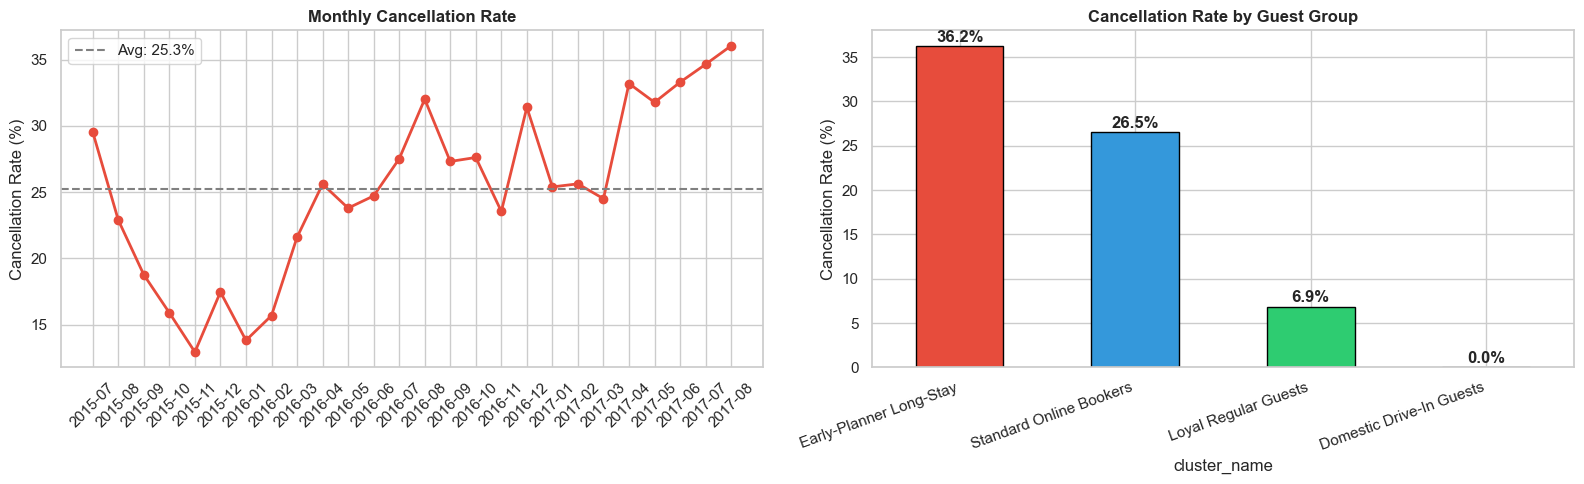

📊 Average monthly cancellation rate: 25.3%
📈 Highest month: 2017-08
📉 Lowest month : 2015-11


In [2]:
monthly_cancel = df.groupby('year_month').agg(
    total_bookings    = ('is_canceled', 'count'),
    total_canceled    = ('is_canceled', 'sum')
).reset_index()

monthly_cancel['cancellation_rate'] = (
    monthly_cancel['total_canceled'] / monthly_cancel['total_bookings'] * 100
).round(2)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly_cancel['year_month'].astype(str),
             monthly_cancel['cancellation_rate'],
             marker='o', color='#e74c3c', linewidth=2)
axes[0].axhline(monthly_cancel['cancellation_rate'].mean(),
                color='gray', linestyle='--',
                label=f"Avg: {monthly_cancel['cancellation_rate'].mean():.1f}%")
axes[0].set_title('Monthly Cancellation Rate', fontweight='bold')
axes[0].set_ylabel('Cancellation Rate (%)')
axes[0].set_xticklabels(monthly_cancel['year_month'].astype(str), rotation=45)
axes[0].legend()

# By cluster
cancel_cluster = df.groupby('cluster_name')['is_canceled'].mean() * 100
cancel_cluster.sort_values(ascending=False).plot(
    kind='bar', ax=axes[1],
    color=['#e74c3c','#3498db','#2ecc71','#f39c12'], edgecolor='black')
axes[1].set_title('Cancellation Rate by Guest Group', fontweight='bold')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')
for i, v in enumerate(cancel_cluster.sort_values(ascending=False)):
    axes[1].text(i, v+0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/metric1_cancellation.png', bbox_inches='tight')
plt.show()

print(f"📊 Average monthly cancellation rate: {monthly_cancel['cancellation_rate'].mean():.1f}%")
print(f"📈 Highest month: {monthly_cancel.loc[monthly_cancel['cancellation_rate'].idxmax(), 'year_month']}")
print(f"📉 Lowest month : {monthly_cancel.loc[monthly_cancel['cancellation_rate'].idxmin(), 'year_month']}")

---
## Metric 2: Average Daily Rate (ADR)
**Formula:** `sum of lodging charges / number of nights stayed`  
**Why it matters:** Tracks revenue per room per night  
**Direction:** ⬆️ Higher is better (within reason)
---

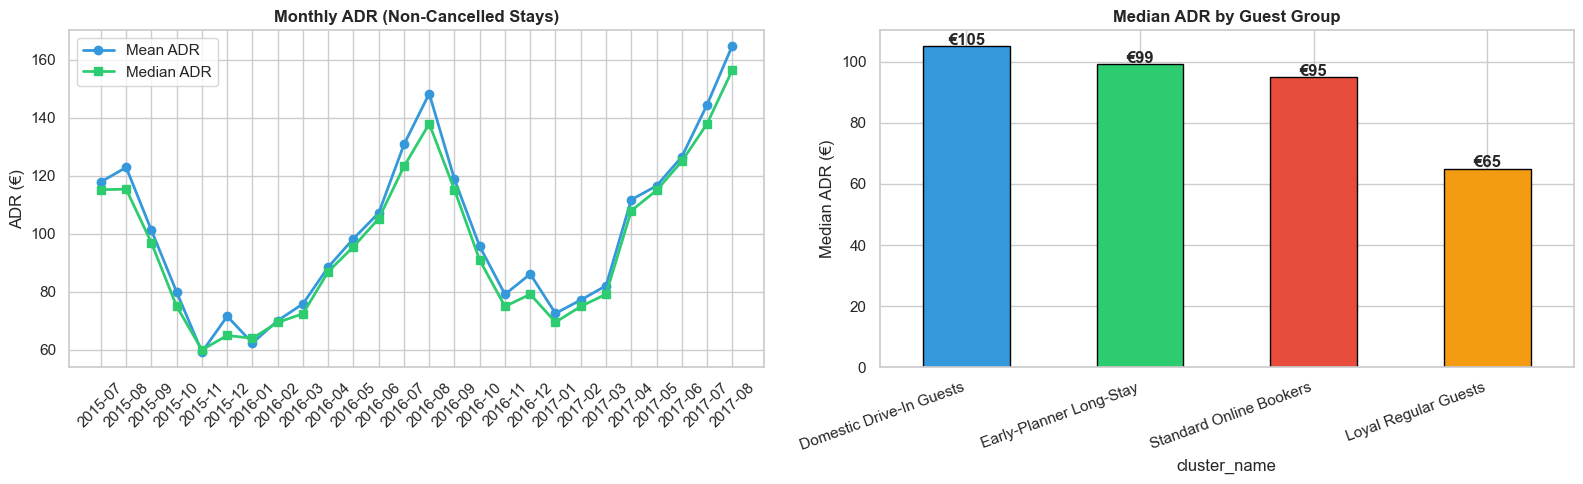

📊 Overall avg ADR: €103.11
📈 Highest month: 2017-08 (€164.88)
📉 Lowest month : 2015-11 (€59.27)


In [3]:
# Only non-cancelled bookings
df_stayed = df[df['is_canceled'] == 0].copy()

monthly_adr = df_stayed.groupby('year_month').agg(
    avg_adr    = ('adr', 'mean'),
    median_adr = ('adr', 'median')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly_adr['year_month'].astype(str),
             monthly_adr['avg_adr'],
             marker='o', color='#3498db', linewidth=2, label='Mean ADR')
axes[0].plot(monthly_adr['year_month'].astype(str),
             monthly_adr['median_adr'],
             marker='s', color='#2ecc71', linewidth=2, label='Median ADR')
axes[0].set_title('Monthly ADR (Non-Cancelled Stays)', fontweight='bold')
axes[0].set_ylabel('ADR (€)')
axes[0].set_xticklabels(monthly_adr['year_month'].astype(str), rotation=45)
axes[0].legend()

# By cluster
adr_cluster = df_stayed.groupby('cluster_name')['adr'].median().sort_values(ascending=False)
adr_cluster.plot(kind='bar', ax=axes[1],
                  color=['#3498db','#2ecc71','#e74c3c','#f39c12'], edgecolor='black')
axes[1].set_title('Median ADR by Guest Group', fontweight='bold')
axes[1].set_ylabel('Median ADR (€)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')
for i, v in enumerate(adr_cluster):
    axes[1].text(i, v+0.5, f'€{v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/metric2_adr.png', bbox_inches='tight')
plt.show()

print(f"📊 Overall avg ADR: €{df_stayed['adr'].mean():.2f}")
print(f"📈 Highest month: {monthly_adr.loc[monthly_adr['avg_adr'].idxmax(), 'year_month']} "
      f"(€{monthly_adr['avg_adr'].max():.2f})")
print(f"📉 Lowest month : {monthly_adr.loc[monthly_adr['avg_adr'].idxmin(), 'year_month']} "
      f"(€{monthly_adr['avg_adr'].min():.2f})")

---
## Metric 3: Nights Sold
**Formula:** `sum of (weekend_nights + week_nights) for non-cancelled bookings`  
**Why it matters:** Tracks actual hotel occupancy  
**Direction:** ⬆️ Higher is better
---

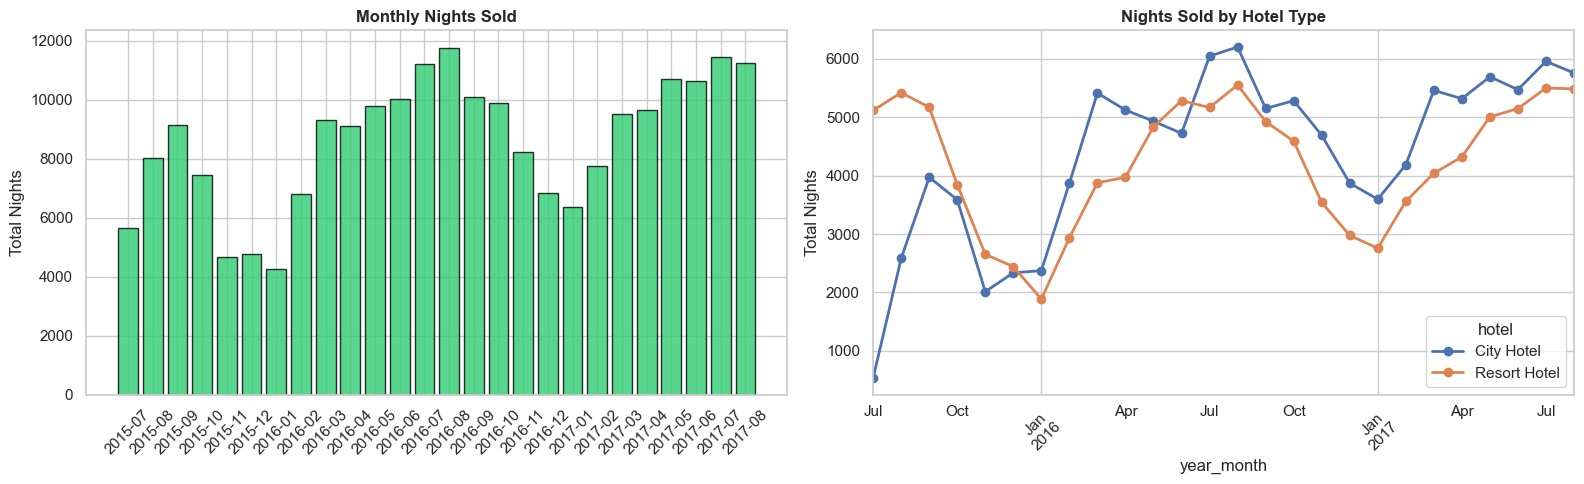

📊 Total nights sold: 224,242
📈 Peak month: 2016-08


In [4]:
df_stayed['total_nights'] = (df_stayed['stays_in_weekend_nights'] +
                              df_stayed['stays_in_week_nights'])

monthly_nights = df_stayed.groupby('year_month').agg(
    nights_sold = ('total_nights', 'sum'),
    avg_nights  = ('total_nights', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(monthly_nights['year_month'].astype(str),
            monthly_nights['nights_sold'],
            color='#2ecc71', edgecolor='black', alpha=0.8)
axes[0].set_title('Monthly Nights Sold', fontweight='bold')
axes[0].set_ylabel('Total Nights')
axes[0].set_xticklabels(monthly_nights['year_month'].astype(str), rotation=45)

# By hotel
nights_hotel = df_stayed.groupby(['year_month','hotel'])['total_nights'].sum().unstack()
nights_hotel.plot(kind='line', ax=axes[1], marker='o', linewidth=2)
axes[1].set_title('Nights Sold by Hotel Type', fontweight='bold')
axes[1].set_ylabel('Total Nights')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('../slides/metric3_nights.png', bbox_inches='tight')
plt.show()

print(f"📊 Total nights sold: {df_stayed['total_nights'].sum():,}")
print(f"📈 Peak month: {monthly_nights.loc[monthly_nights['nights_sold'].idxmax(), 'year_month']}")

---
## Metric 4: Estimated Monthly Revenue
**Formula:** `sum of (ADR × total_nights) for non-cancelled bookings`  
**Why it matters:** Direct measure of hotel income  
**Direction:** ⬆️ Higher is better
---

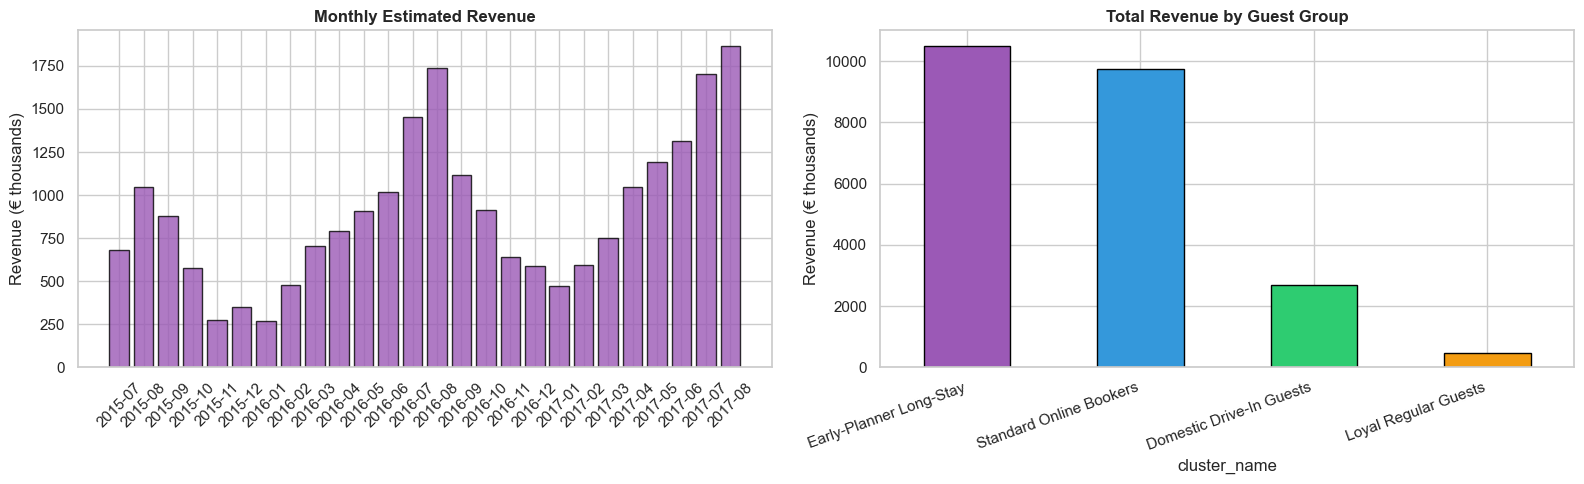

📊 Total estimated revenue: €23,375,782
📈 Best month: 2017-08
   Revenue: €1,862,894


In [5]:
df_stayed['estimated_revenue'] = df_stayed['adr'] * df_stayed['total_nights']

monthly_revenue = df_stayed.groupby('year_month').agg(
    total_revenue = ('estimated_revenue', 'sum')
).reset_index()
monthly_revenue['total_revenue_k'] = monthly_revenue['total_revenue'] / 1000

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(monthly_revenue['year_month'].astype(str),
            monthly_revenue['total_revenue_k'],
            color='#9b59b6', edgecolor='black', alpha=0.8)
axes[0].set_title('Monthly Estimated Revenue', fontweight='bold')
axes[0].set_ylabel('Revenue (€ thousands)')
axes[0].set_xticklabels(monthly_revenue['year_month'].astype(str), rotation=45)

# By cluster
rev_cluster = df_stayed.groupby('cluster_name')['estimated_revenue'].sum().sort_values(ascending=False)
rev_cluster_k = rev_cluster / 1000
rev_cluster_k.plot(kind='bar', ax=axes[1],
                    color=['#9b59b6','#3498db','#2ecc71','#f39c12'], edgecolor='black')
axes[1].set_title('Total Revenue by Guest Group', fontweight='bold')
axes[1].set_ylabel('Revenue (€ thousands)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
plt.savefig('../slides/metric4_revenue.png', bbox_inches='tight')
plt.show()

print(f"📊 Total estimated revenue: €{df_stayed['estimated_revenue'].sum():,.0f}")
print(f"📈 Best month: {monthly_revenue.loc[monthly_revenue['total_revenue'].idxmax(), 'year_month']}")
print(f"   Revenue: €{monthly_revenue['total_revenue'].max():,.0f}")

---
## Metric 5: Average Lead Time
**Formula:** `mean of lead_time (days between booking and arrival)`  
**Why it matters:** Longer lead time = more planning time but higher cancel risk  
**Direction:** 📊 Track for patterns (not simply up or down)
---

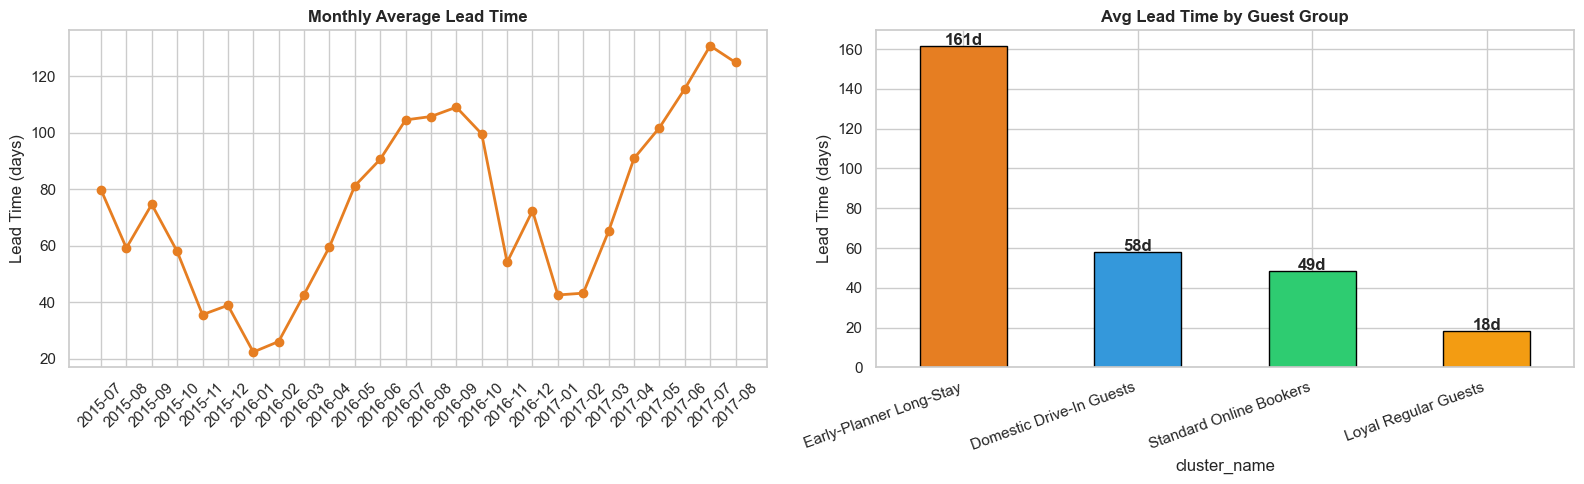

In [6]:
monthly_lead = df.groupby('year_month').agg(
    avg_lead_time    = ('lead_time', 'mean'),
    median_lead_time = ('lead_time', 'median')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly_lead['year_month'].astype(str),
             monthly_lead['avg_lead_time'],
             marker='o', color='#e67e22', linewidth=2)
axes[0].set_title('Monthly Average Lead Time', fontweight='bold')
axes[0].set_ylabel('Lead Time (days)')
axes[0].set_xticklabels(monthly_lead['year_month'].astype(str), rotation=45)

# By cluster
lead_cluster = df.groupby('cluster_name')['lead_time'].mean().sort_values(ascending=False)
lead_cluster.plot(kind='bar', ax=axes[1],
                   color=['#e67e22','#3498db','#2ecc71','#f39c12'], edgecolor='black')
axes[1].set_title('Avg Lead Time by Guest Group', fontweight='bold')
axes[1].set_ylabel('Lead Time (days)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')
for i, v in enumerate(lead_cluster):
    axes[1].text(i, v+0.5, f'{v:.0f}d', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/metric5_leadtime.png', bbox_inches='tight')
plt.show()

---
## Metric 6: No-Show Rate
**Formula:** `bookings with reservation_status = 'No-Show' / total bookings × 100`  
**Why it matters:** No-shows = lost revenue with no time to resell the room  
**Direction:** ⬇️ Lower is better
---

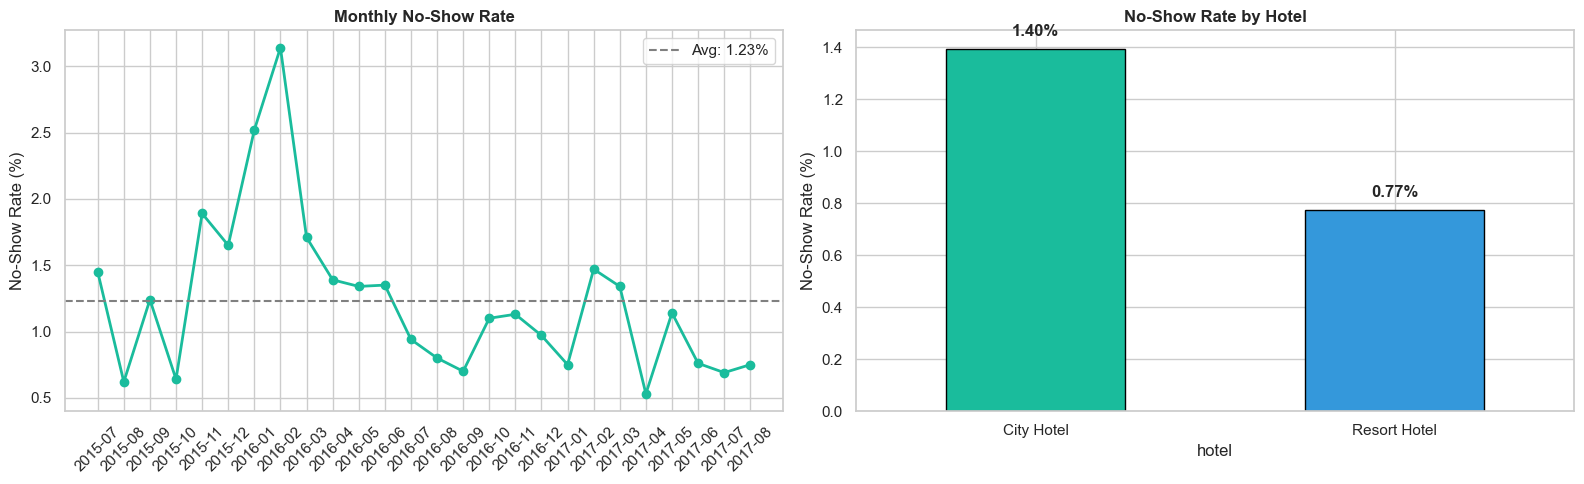

📊 Overall No-Show Rate: 1.15%


In [7]:
monthly_noshow = df.groupby('year_month').agg(
    total     = ('reservation_status', 'count'),
    no_shows  = ('reservation_status', lambda x: (x == 'No-Show').sum())
).reset_index()
monthly_noshow['noshow_rate'] = (
    monthly_noshow['no_shows'] / monthly_noshow['total'] * 100
).round(2)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly_noshow['year_month'].astype(str),
             monthly_noshow['noshow_rate'],
             marker='o', color='#1abc9c', linewidth=2)
axes[0].axhline(monthly_noshow['noshow_rate'].mean(),
                color='gray', linestyle='--',
                label=f"Avg: {monthly_noshow['noshow_rate'].mean():.2f}%")
axes[0].set_title('Monthly No-Show Rate', fontweight='bold')
axes[0].set_ylabel('No-Show Rate (%)')
axes[0].set_xticklabels(monthly_noshow['year_month'].astype(str), rotation=45)
axes[0].legend()

# By hotel
noshow_hotel = df.groupby('hotel').apply(
    lambda x: (x['reservation_status'] == 'No-Show').mean() * 100
).sort_values(ascending=False)
noshow_hotel.plot(kind='bar', ax=axes[1],
                   color=['#1abc9c','#3498db'], edgecolor='black')
axes[1].set_title('No-Show Rate by Hotel', fontweight='bold')
axes[1].set_ylabel('No-Show Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
for i, v in enumerate(noshow_hotel):
    axes[1].text(i, v+0.05, f'{v:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/metric6_noshow.png', bbox_inches='tight')
plt.show()

print(f"📊 Overall No-Show Rate: {(df['reservation_status']=='No-Show').mean()*100:.2f}%")

## Monthly Summary Table

In [8]:
# Merge all metrics into one table
monthly_all = (monthly_cancel[['year_month','cancellation_rate']]
    .merge(monthly_adr[['year_month','avg_adr']], on='year_month')
    .merge(monthly_nights[['year_month','nights_sold']], on='year_month')
    .merge(monthly_revenue[['year_month','total_revenue']], on='year_month')
    .merge(monthly_lead[['year_month','avg_lead_time']], on='year_month')
    .merge(monthly_noshow[['year_month','noshow_rate']], on='year_month')
)

monthly_all.columns = [
    'Month', 'Cancel Rate %', 'Avg ADR €',
    'Nights Sold', 'Revenue €', 'Avg Lead Time', 'No-Show Rate %'
]
monthly_all['Revenue €'] = monthly_all['Revenue €'].round(0)
monthly_all['Avg ADR €'] = monthly_all['Avg ADR €'].round(2)
monthly_all['Avg Lead Time'] = monthly_all['Avg Lead Time'].round(1)

print("📋 MONTHLY METRICS SUMMARY TABLE")
monthly_all

📋 MONTHLY METRICS SUMMARY TABLE


,Month,Cancel Rate %,Avg ADR €,Nights Sold,Revenue €,Avg Lead Time,No-Show Rate %
0,2015-07,29.54,117.98,5655,682827.0,79.8,1.45
1,2015-08,22.90,122.93,8006,1048360.0,59.2,0.62
2,2015-09,18.77,101.22,9146,879374.0,74.7,1.24
3,2015-10,15.90,79.93,7436,579293.0,58.0,0.64
4,2015-11,12.94,59.27,4668,275782.0,35.6,1.89
5,2015-12,17.47,71.60,4781,353220.0,39.0,1.65
6,2016-01,13.82,62.39,4261,268699.0,22.4,2.52
7,2016-02,15.69,70.10,6806,478311.0,26.2,3.14
8,2016-03,21.60,75.89,9295,704715.0,42.8,1.71
9,2016-04,25.61,88.57,9099,790312.0,59.6,1.39


## Unusual Months Analysis

In [9]:
print("=" * 60)
print("🔍 UNUSUAL MONTHS ANALYSIS")
print("=" * 60)

# High cancellation months
high_cancel = monthly_all[monthly_all['Cancel Rate %'] >
                           monthly_all['Cancel Rate %'].mean() +
                           monthly_all['Cancel Rate %'].std()]
print(f"\n⚠️ Months with UNUSUALLY HIGH cancellation rate:")
print(high_cancel[['Month','Cancel Rate %']].to_string(index=False))

# Low revenue months
low_rev = monthly_all.nsmallest(3, 'Revenue €')
print(f"\n⚠️ Months with LOWEST revenue:")
print(low_rev[['Month','Revenue €']].to_string(index=False))

# Peak months
peak = monthly_all.nlargest(3, 'Revenue €')
print(f"\n✅ Months with HIGHEST revenue:")
print(peak[['Month','Revenue €']].to_string(index=False))

print(f"""
💡 EXPLANATIONS:
- High cancellation in certain months may be linked to high lead time bookings
- Revenue peaks in summer (July-August) match the seasonality finding from Task 2
- Low revenue in January-February = low season for Portuguese hotels
- 2015 shows partial year (data starts July 2015)
- 2017 shows partial year (data ends August 2017)
""")

🔍 UNUSUAL MONTHS ANALYSIS

⚠️ Months with UNUSUALLY HIGH cancellation rate:
  Month  Cancel Rate %
2016-08          32.02
2017-04          33.20
2017-06          33.30
2017-07          34.65
2017-08          36.05

⚠️ Months with LOWEST revenue:
  Month  Revenue €
2016-01   268699.0
2015-11   275782.0
2015-12   353220.0

✅ Months with HIGHEST revenue:
  Month  Revenue €
2017-08  1862894.0
2016-08  1739956.0
2017-07  1703166.0

💡 EXPLANATIONS:
- High cancellation in certain months may be linked to high lead time bookings
- Revenue peaks in summer (July-August) match the seasonality finding from Task 2
- Low revenue in January-February = low season for Portuguese hotels
- 2015 shows partial year (data starts July 2015)
- 2017 shows partial year (data ends August 2017)



## Forecast Last 3 Months

🎯 BONUS: Forecast Cancellation Rate - Last 3 Months

Month            Actual   Forecast      Error
---------------------------------------------
2017-06           33.3%      29.8%       3.5%
2017-07           34.6%      32.8%       1.9%
2017-08           36.0%      33.2%       2.8%

📊 Mean Absolute Error: 2.72%


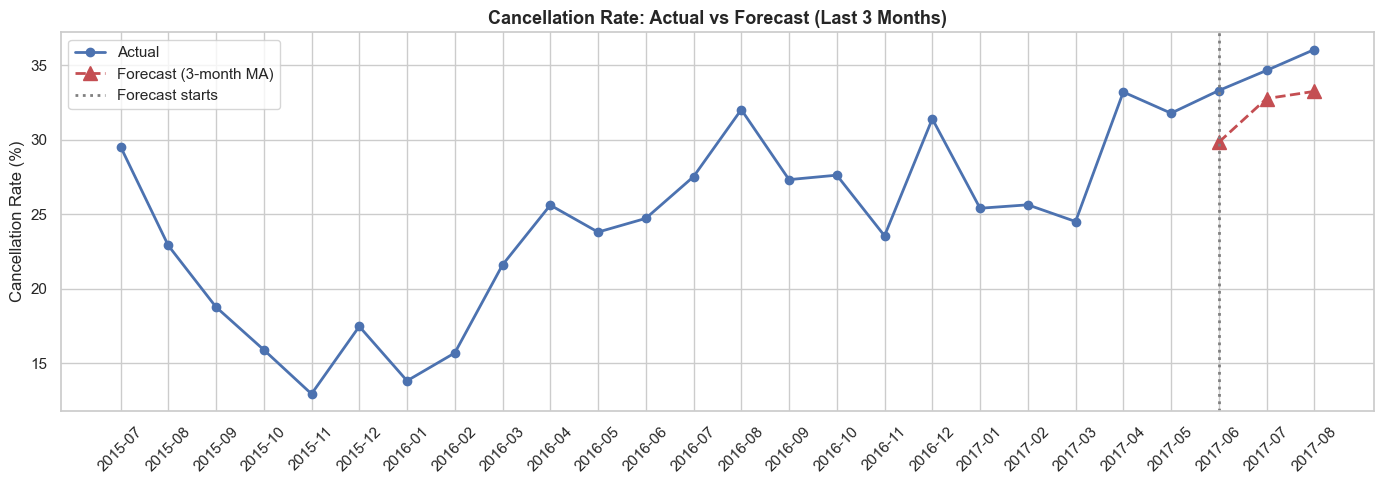

In [10]:
print("=" * 60)
print("🎯 BONUS: Forecast Cancellation Rate - Last 3 Months")
print("=" * 60)

# Use simple moving average on training months
monthly_all['Month_str'] = monthly_all['Month'].astype(str)
cancel_series = monthly_all['Cancel Rate %'].values

# Split: train = all except last 3, test = last 3
train = cancel_series[:-3]
test  = cancel_series[-3:]

# Simple 3-month moving average forecast
window = 3
forecasts = []
history = list(train)
for i in range(3):
    pred = np.mean(history[-window:])
    forecasts.append(pred)
    history.append(test[i])

# Results
test_months = monthly_all['Month_str'].values[-3:]
print(f"\n{'Month':<12} {'Actual':>10} {'Forecast':>10} {'Error':>10}")
print("-" * 45)
for m, actual, pred in zip(test_months, test, forecasts):
    err = abs(actual - pred)
    print(f"{m:<12} {actual:>9.1f}% {pred:>9.1f}% {err:>9.1f}%")

mae = np.mean(np.abs(np.array(test) - np.array(forecasts)))
print(f"\n📊 Mean Absolute Error: {mae:.2f}%")

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
x_all   = monthly_all['Month_str'].values
x_train = x_all[:-3]
x_test  = x_all[-3:]

ax.plot(x_all, cancel_series, 'bo-', linewidth=2, label='Actual')
ax.plot(x_test, forecasts, 'r^--', linewidth=2, markersize=10, label='Forecast (3-month MA)')
ax.axvline(x=x_test[0], color='gray', linestyle=':', linewidth=2, label='Forecast starts')
ax.set_title('Cancellation Rate: Actual vs Forecast (Last 3 Months)',
              fontweight='bold', fontsize=13)
ax.set_ylabel('Cancellation Rate (%)')
ax.set_xticklabels(x_all, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig('../slides/metric_forecast.png', bbox_inches='tight')
plt.show()